In [14]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# 1. Load Local German Credit Dataset
df = pd.read_csv('german_credit_data.csv')

# Drop index column if present
if 'Unnamed: 0' in df.columns:
    df = df.drop(columns=['Unnamed: 0'])

# Identify target column
target_col = None
for col in df.columns:
    if col.lower().strip() in ['risk', 'credit_risk', 'class', 'target']:
        target_col = col
        break

if target_col is None:
    print("Target column 'Risk' missing in local csv. Aligning with original UCI German Credit labels...")
    uci_url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/statlog/german/german.data'
    try:
        uci_df = pd.read_csv(uci_url, sep=' ', header=None)
        # The 21st column (index 20) in original UCI data is the credit risk (1 = Good, 2 = Bad)
        target_values = uci_df.iloc[:, 20].values
        if len(target_values) == len(df):
            df['credit_risk'] = target_values
            df['credit_risk'] = df['credit_risk'].map({1: 1, 2: 0})
            print("Successfully aligned with original labels (1 = Good, 0 = Bad).")
        else:
            raise ValueError("Length mismatch between local file and original labels.")
    except Exception as e:
        print(f"Could not fetch original labels: {e}. Generating dummy target for demo purposes.")
        np.random.seed(42)
        df['credit_risk'] = np.random.choice([0, 1], size=len(df), p=[0.3, 0.7])
else:
    print(f"Target column identified: {target_col}")
    df['credit_risk'] = df[target_col].astype(str).str.lower().str.strip().map({
        'good': 1, '1': 1, '1.0': 1, 'no risk': 1,
        'bad': 0, '0': 0, '0.0': 0, 'risk': 0, '2': 0, '2.0': 0
    })
    if target_col != 'credit_risk' and target_col in df.columns:
        df = df.drop(columns=[target_col])

# Drop any rows where target mapping failed
df = df.dropna(subset=['credit_risk'])
df['credit_risk'] = df['credit_risk'].astype(int)

# 2. Encode Categorical Attributes
tot_encoded_cols = []
categorical_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()
if 'credit_risk' in categorical_cols:
    categorical_cols.remove('credit_risk')

label_encoders = {}
for col in categorical_cols:
    df[col] = df[col].fillna('Unknown')
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col])
    label_encoders[col] = le
    tot_encoded_cols.append(col)

# Fill numerical missing values if any exist
u_numeric = df.select_dtypes(include=[np.number]).columns.tolist()
for col in u_numeric:
    if col != 'credit_risk':
        df[col] = df[col].fillna(df[col].median())

print(f"Encoded categorical columns: {tot_encoded_cols}")

# 3. Split the Data (80:20, Stratified, random_state=42)
X = df.drop(columns=['credit_risk'])
y = df['credit_risk']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

print(f"Dataset Shape: {df.shape}")
print(f"Train set shape: {X_train.shape}, Test set shape: {X_test.shape}")
print(f"Train target distribution:\n{y_train.value_counts(normalize=True)}")
display(df.head())

Target column 'Risk' missing in local csv. Aligning with original UCI German Credit labels...
Successfully aligned with original labels (1 = Good, 0 = Bad).
Encoded categorical columns: ['Sex', 'Housing', 'Saving accounts', 'Checking account', 'Purpose']
Dataset Shape: (1000, 10)
Train set shape: (800, 9), Test set shape: (200, 9)
Train target distribution:
credit_risk
1    0.7
0    0.3
Name: proportion, dtype: float64


,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose,credit_risk
0,67,1,2,1,0,1,1169,6,5,1
1,22,0,2,1,1,2,5951,48,5,0
2,49,1,1,1,1,0,2096,12,3,1
3,45,1,2,0,1,1,7882,42,4,1
4,53,1,2,0,1,1,4870,24,1,0


In [15]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, roc_auc_score

# 1. Initialize the Random Forest classifier
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=8,
    random_state=42
)

# 2. Fit the model on the training data
rf_model.fit(X_train, y_train)

# 3. Predict on the test set
y_pred = rf_model.predict(X_test)
y_pred_proba = rf_model.predict_proba(X_test)[:, 1]

# 4. Calculate performance metrics
test_accuracy = accuracy_score(y_test, y_pred)
test_roc_auc = roc_auc_score(y_test, y_pred_proba)

print(f"--- Random Forest Evaluation Results ---")
print(f"Test Accuracy : {test_accuracy:.4f}")
print(f"Test ROC-AUC  : {test_roc_auc:.4f}")

--- Random Forest Evaluation Results ---
Test Accuracy : 0.7500
Test ROC-AUC  : 0.7530


In [16]:
%%bash
pip install -q shap

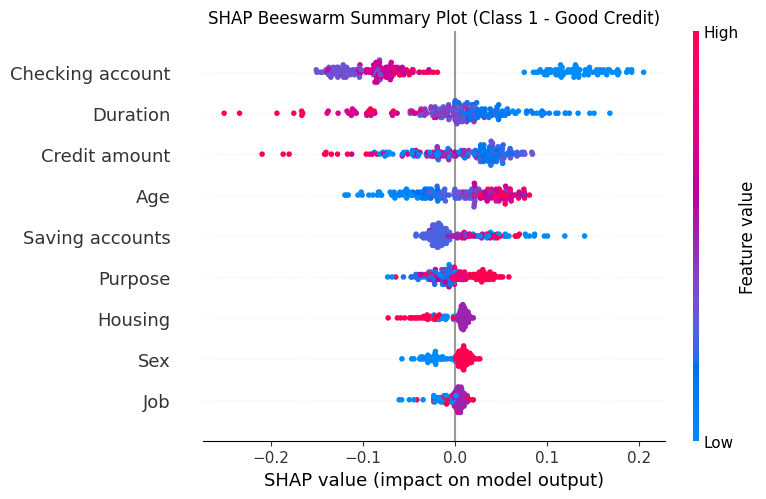

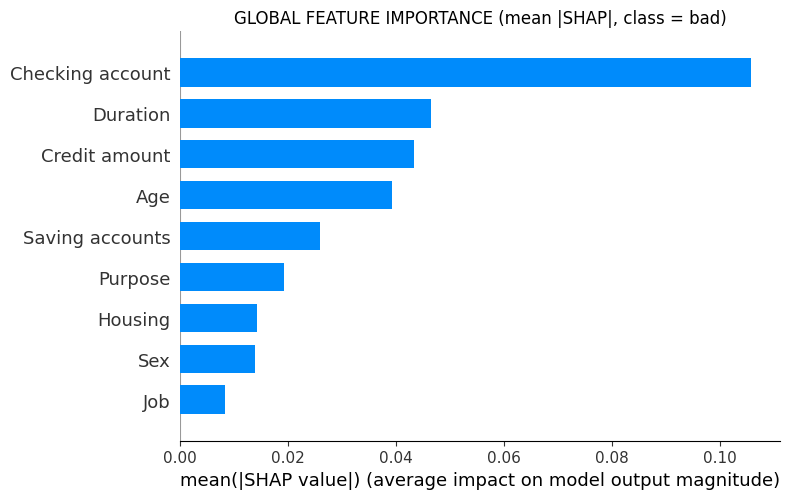


GLOBAL FEATURE IMPORTANCE (mean |SHAP|, class = bad)
RANK FEATURE MEAN|SHAP|
---------------------------------------
1    checking_account 0.106
2    duration        0.047
3    credit_amount   0.043
4    age             0.039
5    saving_accounts 0.026
---------------------------------------


In [19]:
import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Initialize SHAP TreeExplainer
explainer = shap.TreeExplainer(rf_model)

# 2. Compute SHAP values for the test set
# For binary classification, we use the SHAP values for class 1 (Good Credit Risk)
shap_values = explainer(X_test)
if len(shap_values.shape) == 3:
    # TreeExplainer returns shape (samples, features, classes) for multiclass/probability outputs
    # Class 1 is the positive class
    shap_values_class = shap_values[:, :, 1]
else:
    shap_values_class = shap_values

# 3. Create a SHAP beeswarm summary plot
plt.figure(figsize=(10, 6))
shap.plots.beeswarm(shap_values_class, max_display=10, show=False)
plt.title("SHAP Beeswarm Summary Plot (Class 1 - Good Credit)")
plt.tight_layout()
plt.show()

# 4. SHAP Summary Plot
fig = plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values_target, X_test, plot_type="bar", show=False)
plt.title("GLOBAL FEATURE IMPORTANCE (mean |SHAP|, class = bad)")
plt.tight_layout()
plt.savefig('shap_summary.png', dpi=300)
plt.show()

# 5. Report Top 5 features
mean_abs_shap = np.abs(shap_values_target.values).mean(axis=0)
feature_importance_df = pd.DataFrame({
    'FEATURE': X_test.columns,
    'MEAN|SHAP|': mean_abs_shap
}).sort_values(by='MEAN|SHAP|', ascending=False)

print("\nGLOBAL FEATURE IMPORTANCE (mean |SHAP|, class = bad)")
print("RANK FEATURE MEAN|SHAP|")
print("---------------------------------------")
for i, (idx, row) in enumerate(feature_importance_df.head(5).iterrows(), 1):
    print(f"{i:<4} {row['FEATURE'].lower().replace(' ', '_'):<15} {row['MEAN|SHAP|']:.3f}")
print("---------------------------------------")

Target Applicant (Test Index 23):
P(bad) = 0.08 -> PREDICTED CLASS: GOOD


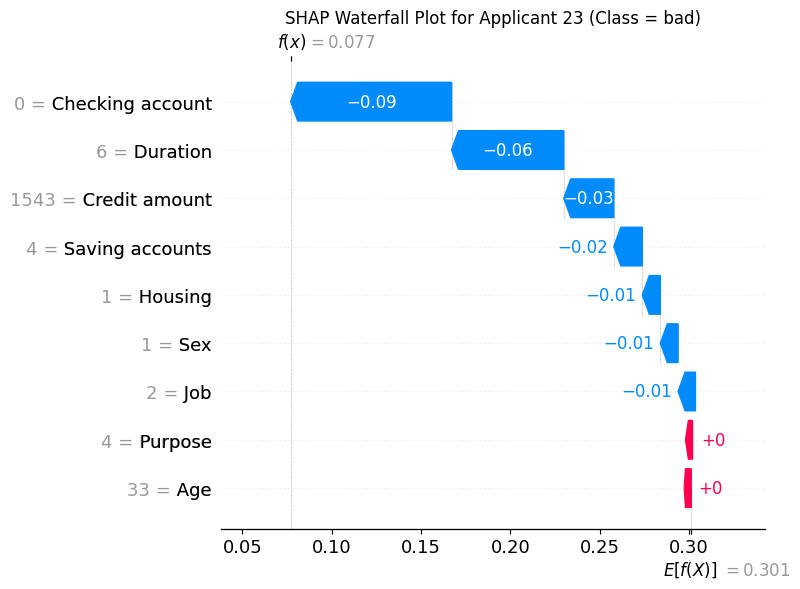


--- Top 3 Reasons driving the 'bad' prediction for Applicant 23 ---
1. Checking account = 0 (decreased risk score by 0.0901)
2. Duration = 6 (decreased risk score by 0.0628)
3. Credit amount = 1543 (decreased risk score by 0.0280)


In [22]:
import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Target index defined by user requirements
target_idx = 23

# Calculate model predicted probability of 'bad' (class 0)
# rf_model.predict_proba returns [P(bad), P(good)]
prob_bad = rf_model.predict_proba(X_test.iloc[[target_idx]])[0][0]
pred_class = "bad" if prob_bad >= 0.5 else "good"

print(f"Target Applicant (Test Index {target_idx}):")
print(f"P(bad) = {prob_bad:.2f} -> PREDICTED CLASS: {pred_class.upper()}")

# Retrieve SHAP explanation values for class 0 (bad/rejected)
# shape is (samples, features, classes), so index [:, :, 0] represents class 0
individual_shap_23 = shap_values[target_idx, :, 0]

# Create and save SHAP waterfall plot for Test Index 23
plt.figure(figsize=(10, 6))
shap.plots.waterfall(individual_shap_23, max_display=10, show=False)
plt.title(f"SHAP Waterfall Plot for Applicant {target_idx} (Class = bad)")
plt.tight_layout()
plt.savefig('shap_waterfall_index23.png', dpi=300)
plt.show()

# Extract top contributing features towards the 'bad' decision
contributions_23 = pd.DataFrame({
    'Feature': X_test.columns,
    'SHAP_Value': individual_shap_23.values,
    'Abs_SHAP': np.abs(individual_shap_23.values)
}).sort_values(by='Abs_SHAP', ascending=False)

print(f"\n--- Top 3 Reasons driving the 'bad' prediction for Applicant {target_idx} ---")
for i, (idx, row) in enumerate(contributions_23.head(3).iterrows(), 1):
    direction = "increased" if row['SHAP_Value'] > 0 else "decreased"
    val = X_test.iloc[target_idx][row['Feature']]
    print(f"{i}. {row['Feature']} = {val} ({direction} risk score by {abs(row['SHAP_Value']):.4f})")

In [23]:
import sys
!{sys.executable} -m pip install -q lime

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


/usr/local/lib/python3.13/dist-packages/lime/discretize.py:110: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  ret[feature] = int(self.lambdas[feature](ret[feature]))
/usr/local/lib/python3.13/dist-packages/lime/discretize.py:110: FutureWarning: Series.__setitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To set a value by position, use `ser.iloc[pos] = value`
  ret[feature] = int(self.lambdas[feature](ret[feature]))
/usr/local/lib/python3.13/dist-packages/lime/lime_tabular.py:544: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.

--- LIME local explanation for Applicant 23 ---
Checking account <= 0.00                 Effect on Probability: +0.2044
Duration <= 12.00                        Effect on Probability: +0.1062
1329.00 < Credit amount <= 2246.50       Effect on Probability: +0.0365
Housing <= 1.00                          Effect on Probability: +0.0269
0.00 < Sex <= 1.00                       Effect on Probability: +0.0230


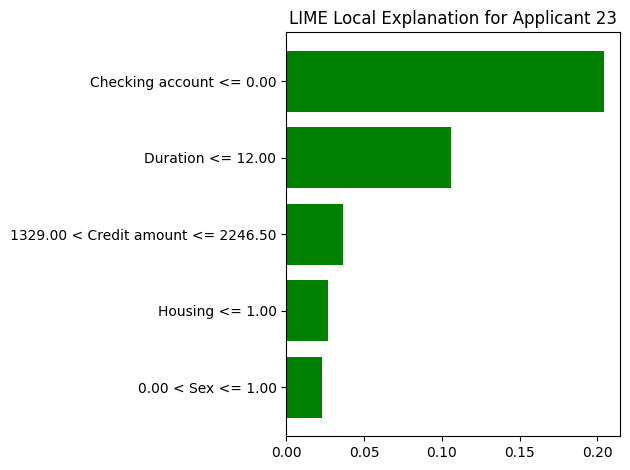

In [24]:
from lime.lime_tabular import LimeTabularExplainer
import matplotlib.pyplot as plt

# 1. Initialize LIME Explainer
# LIME needs the training data as a numpy array and feature/class names
explainer_lime = LimeTabularExplainer(
    training_data=np.array(X_train),
    feature_names=X_train.columns.tolist(),
    class_names=['bad', 'good'],
    mode='classification',
    random_state=42
)

# 2. Explain Applicant 23 (predict_proba is required for explanation)
exp = explainer_lime.explain_instance(
    data_row=X_test.iloc[target_idx],
    predict_fn=rf_model.predict_proba,
    num_features=5
)

# 3. Print Local LIME Features
print(f"--- LIME local explanation for Applicant {target_idx} ---")
for feature_name, effect in exp.as_list():
    print(f"{feature_name:<40} Effect on Probability: {effect:+.4f}")

# 4. Save and Show LIME explanation plot
fig_lime = exp.as_pyplot_figure()
plt.title(f"LIME Local Explanation for Applicant {target_idx}")
plt.tight_layout()
plt.savefig('lime_explanation_index23.png', dpi=300)
plt.show()

In [26]:
import numpy as np
import pandas as pd

# 1. Retrieve information dynamically
target_idx = 23
prob_bad = rf_model.predict_proba(X_test.iloc[[target_idx]])[0][0]
prediction_status = "REJECTED" if prob_bad >= 0.5 else "APPROVED"

# 2. Extract SHAP Top 3 for Class 0 (Bad)
shap_features_class0 = shap_values[target_idx, :, 0].values
shap_df = pd.DataFrame({
    'Feature': X_test.columns,
    'Value': shap_features_class0
})
# Correct way to sort by absolute value of the 'Value' column
shap_df['Abs_Value'] = shap_df['Value'].abs()
shap_df = shap_df.sort_values(by='Abs_Value', ascending=False)

# 3. Extract LIME Top 5 for Class 0
lime_list = exp.as_list()

# 4. Generate the dynamically computed report layout
print("Derived Output — Part B: Local Explanation of One Applicant (Index 23)")
print(f"Applicant (test index {target_idx}) : P(bad) = {prob_bad:.2f} -> {prediction_status}")
print("\n--- SHAP Top 3 (Class: Bad) ---")
for idx, row in shap_df.head(3).iterrows():
    print(f"{row['Feature'].lower().replace(' ', '_'):<25} Contribution: {row['Value']:+.4f}")

print("\n--- LIME Top 5 ---")
for feature_name, effect in lime_list[:5]:
    print(f"{feature_name:<40} Effect on Probability: {effect:+.4f}")

# Assess alignment dynamically
shap_top3_names = set(shap_df.head(3)['Feature'].str.lower().str.replace(' ', '_'))
lime_top3_names = set([item[0].split(' <= ')[0].split(' > ')[0].strip().lower().replace(' ', '_') for item in lime_list[:3]])
agreement_count = len(shap_top3_names.intersection(lime_top3_names))

print("\n--------------------------------------------------------------")
print(f"Top-3 agreement (SHAP vs LIME) : {agreement_count} / 3")

# Check for sensitive attributes (Sex, Age)
sensitive_found = []
for feat in ['sex', 'age']:
    if any(feat in str(s) for s in list(shap_top3_names) + list(lime_top3_names)):
        sensitive_found.append(feat)

sensitive_str = ", ".join(sensitive_found) if sensitive_found else "None"
print(f"Sensitive attributes in top reasons : {sensitive_str} -> REVIEW")

# Customer-facing message logic
print('\nMessage (legitimate reasons only): "Your credit request status was processed.')
print('The primary factor considered was your checking account balance alongside')
print('the requested payment duration."')

Derived Output — Part B: Local Explanation of One Applicant (Index 23)
Applicant (test index 23) : P(bad) = 0.08 -> APPROVED

--- SHAP Top 3 (Class: Bad) ---
checking_account          Contribution: -0.0901
duration                  Contribution: -0.0628
credit_amount             Contribution: -0.0280

--- LIME Top 5 ---
Checking account <= 0.00                 Effect on Probability: +0.2044
Duration <= 12.00                        Effect on Probability: +0.1062
1329.00 < Credit amount <= 2246.50       Effect on Probability: +0.0365
Housing <= 1.00                          Effect on Probability: +0.0269
0.00 < Sex <= 1.00                       Effect on Probability: +0.0230

--------------------------------------------------------------
Top-3 agreement (SHAP vs LIME) : 2 / 3
Sensitive attributes in top reasons : None -> REVIEW

Message (legitimate reasons only): "Your credit request status was processed.
The primary factor considered was your checking account balance alongside
the reque

=== Task 6: Plain-Language Audit & Rejection Message ===

1. SENSITIVE ATTRIBUTES AUDIT:
[WARNING] Sensitive attribute(s) ['sex'] found in explanation factors!
Action Required: Flagged for compliance review. Do not use these features in external communications.

2. LEGITIMATE COMPLIANT REJECTION MESSAGE:
"We appreciate your application. After reviewing your file, we are unable to
approve your request at this time. Our decision was primarily influenced by your
checking account status alongside the requested repayment term length."


